# Radiographic Weld Defect Classification on RIAWELC — ResNet50
### Known-Weld Inspection Protocol · Notebook 01 of 03

**Pipeline:** radiographic patch → intensity normalisation → YOLO defect localisation (when box annotations are available) → ResNet50 (ImageNet transfer learning + full fine-tuning) → four-class defect classification → evaluation and Grad-CAM explainability.

**Evaluation protocol (known-weld inspection):** test images are patches and radiographs not used in training, drawn from welds that are represented in the training set. Exact duplicate files are removed before training, retaining the test copy, so that no test image is present in the training data.

**Companion notebooks:** `01_ResNet50`, `02_EfficientNet-B3`, `03_ConvNeXt-Tiny`. All three share an identical split, preprocessing, augmentation and training schedule. The final section of each notebook compiles a cross-model comparison and soft-voting ensemble from whichever notebooks have been run.

## 1. Environment Setup

### 1.1 Install Dependencies

In [1]:
!pip -q install timm ultralytics


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### 1.2 Import Libraries

In [2]:
import os, re, json, math, time, random, hashlib, shutil, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, roc_auc_score, roc_curve,
                             cohen_kappa_score, matthews_corrcoef)
from sklearn.preprocessing import label_binarize

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

c:\Users\dipkh\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.3 Experiment Configuration

In [3]:
MODEL_KEY = "ResNet50"
TIMM_NAME = "resnet50.a1_in1k"

DATA_ROOT  = Path(r"C:\Users\dipkh\Downloads\RIAWELC-main(24k images)\RIAWELC-main\Dataset_partitioned")
PROTOCOL   = "official_dedup"
SHARED_DIR = Path("./riawelc_outputs") / PROTOCOL / "_shared"
OUT_DIR    = Path("./riawelc_outputs") / PROTOCOL / MODEL_KEY

CLASS_ORDER   = ["Difetto1", "Difetto2", "Difetto4", "NoDifetto"]
DISPLAY_NAMES = {"Difetto1": "Difetto1", "Difetto2": "Difetto2", "Difetto4": "Difetto4", "NoDifetto": "No Defect"}

TEST_FRAC, VAL_FRAC = 0.15, 0.15

YOLO_LABEL_DIR = None
YOLO_DET_MODEL = "yolov8s.pt"
YOLO_DET_EPOCHS, YOLO_IMGSZ, YOLO_CONF, CROP_PAD = 100, 256, 0.25, 0.10

IMG_SIZE        = 224
BATCH_SIZE      = 64
EPOCHS          = 30
FREEZE_EPOCHS   = 2
WARMUP_EPOCHS   = 2
LR_HEAD         = 1e-3
LR_BACKBONE     = 1e-4
WEIGHT_DECAY    = 0.05
LABEL_SMOOTHING = 0.1
PATIENCE        = 7
INTENSITY_NORM  = True
STRONG_AUG      = True
USE_TTA         = True
N_BOOTSTRAP     = 1000
SEED            = 42
NUM_WORKERS     = 0 if os.name == "nt" else min(8, os.cpu_count() or 2)

assert PROTOCOL in {"official_dedup", "radiograph"}
for d in [OUT_DIR / "figures", SHARED_DIR / "predictions"]:
    d.mkdir(parents=True, exist_ok=True)
NUM_CLASSES = len(CLASS_ORDER)
LABEL2ID = {c: i for i, c in enumerate(CLASS_ORDER)}
NAMES = [DISPLAY_NAMES.get(c, c) for c in CLASS_ORDER]

DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
torch.backends.cudnn.benchmark = True

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything()
assert DATA_ROOT.exists(), f"DATA_ROOT not found: {DATA_ROOT}"
print(f"Model: {MODEL_KEY} ({TIMM_NAME}) | Protocol: {PROTOCOL} | Device: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if USE_AMP else ""))

Model: ResNet50 (resnet50.a1_in1k) | Protocol: official_dedup | Device: cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


## 2. Dataset Indexing

### 2.1 Build the Image Index

In [4]:
SPLIT_ALIASES = {"training": "train", "train": "train", "validation": "val", "val": "val", "testing": "test", "test": "test"}
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def parse_ids(fname):
    stem = Path(fname).stem
    base = stem.split("_[")[0]
    m = re.match(r"^(.*?)_Img(\d+)", base)
    if m:
        return m.group(1), f"{m.group(1)}_Img{m.group(2)}"
    return base.split("_")[0], base

def index_dataset(root):
    rows, empty = [], []
    for dirpath, dirnames, filenames in os.walk(root):
        imgs = [f for f in filenames if Path(f).suffix.lower() in IMG_EXT]
        rel = Path(dirpath).relative_to(root).parts
        if not imgs and not dirnames:
            empty.append("/".join(rel))
        for f in imgs:
            split = next((SPLIT_ALIASES[x.lower()] for x in rel if x.lower() in SPLIT_ALIASES), None)
            part = next((x for x in rel if "part" in x.lower()), "NA")
            weld, radiograph = parse_ids(f)
            rows.append(dict(path=str(Path(dirpath) / f), file=f, part=part, official_split=split,
                             cls=Path(dirpath).name, weld=weld, radiograph=radiograph))
    return pd.DataFrame(rows), empty

df_all, empty_dirs = index_dataset(DATA_ROOT)
assert len(df_all), f"No images found under {DATA_ROOT}"
df_all = df_all[df_all.cls.isin(CLASS_ORDER)].sort_values("path").reset_index(drop=True)
df_all["label"] = df_all.cls.map(LABEL2ID)
df_all["source"] = df_all.weld.str.extract(r"^([A-Za-z]+)", expand=False).fillna("other")
print(f"Images: {len(df_all):,} | welds: {df_all.weld.nunique()} | radiographs: {df_all.radiograph.nunique()} "
      f"| empty leaf folders: {len(empty_dirs)}")

Images: 244,102 | welds: 29 | radiographs: 109 | empty leaf folders: 108


### 2.2 Class and Split Distribution

In [5]:
display(pd.crosstab(df_all.official_split, df_all.cls, margins=True))

cls,Difetto1,Difetto2,Difetto4,NoDifetto,All
official_split,,,,,
test,765,752,892,1200,3609
train,21202,32097,31492,52200,136991
val,29281,26244,19780,28197,103502
All,51248,59093,52164,81597,244102


### 2.3 Sample Visualisation

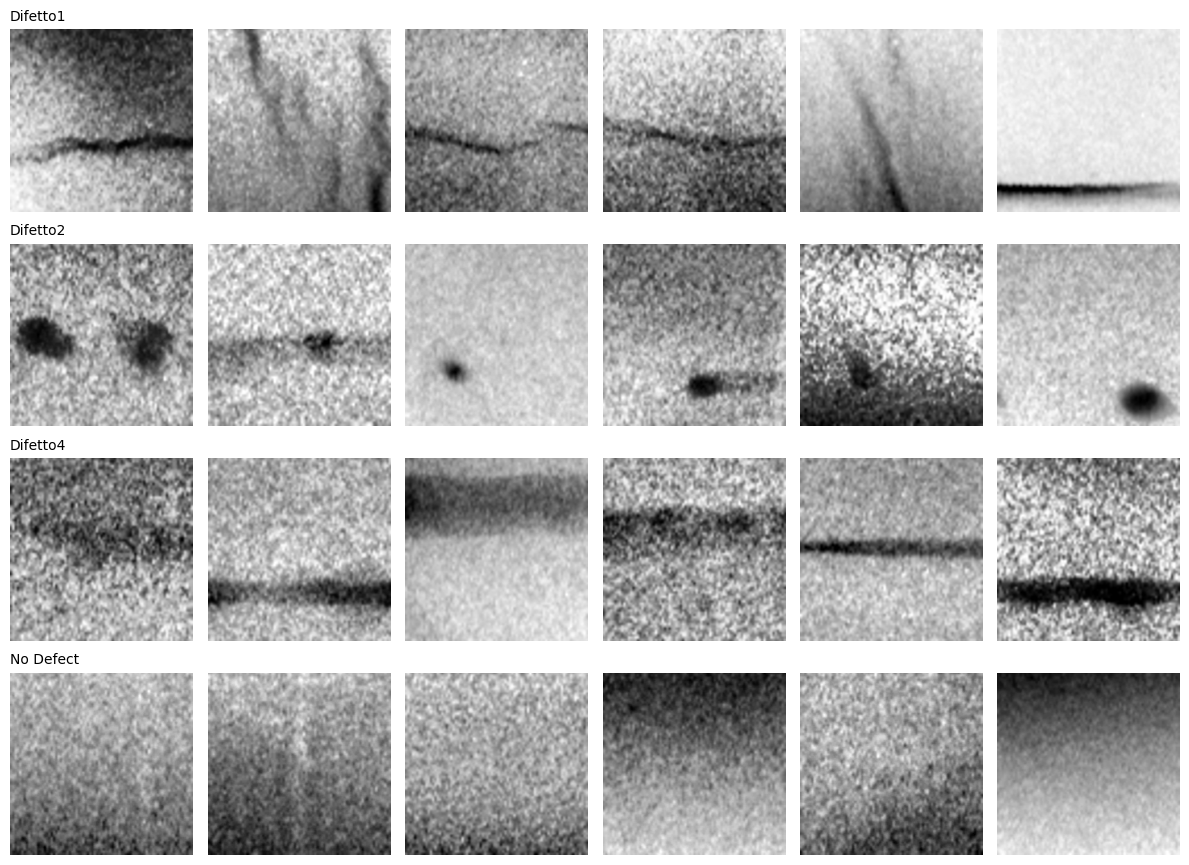

In [6]:
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(12, 2.2 * NUM_CLASSES))
for r, c in enumerate(CLASS_ORDER):
    sub = df_all[df_all.cls == c].sample(min(6, (df_all.cls == c).sum()), random_state=SEED)
    for k in range(6):
        ax = axes[r, k]; ax.axis("off")
        if k < len(sub):
            ax.imshow(Image.open(sub.path.iloc[k]).convert("L"), cmap="gray")
        if k == 0:
            ax.set_title(DISPLAY_NAMES[c], loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(OUT_DIR / "figures/samples.png", dpi=150); plt.show()

## 3. Data Integrity Audit

### 3.1 Exact-Duplicate Detection

In [7]:
def md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

hash_cache = SHARED_DIR / "md5_cache.csv"
if hash_cache.exists():
    cache = pd.read_csv(hash_cache).set_index("path").md5.to_dict()
else:
    cache = {}
df_all["md5"] = [cache.get(p) or md5(p) for p in df_all.path]
df_all[["path", "md5"]].to_csv(hash_cache, index=False)

test_h, train_h, val_h = (set(df_all.loc[df_all.official_split == s, "md5"]) for s in ["test", "train", "val"])
audit = pd.DataFrame({
    "check": ["Test images with an identical copy in train", "Test images with an identical copy in val",
              "Val images with an identical copy in train", "Hashes shared by more than one file"],
    "count": [len(test_h & train_h), len(test_h & val_h), len(val_h & train_h),
              int((df_all.groupby("md5").size() > 1).sum())]})
display(audit)

,check,count
0,Test images with an identical copy in train,2444
1,Test images with an identical copy in val,1
2,Val images with an identical copy in train,1
3,Hashes shared by more than one file,21965


### 3.2 Duplicate Removal (Test Copy Retained)

In [8]:
conflict = df_all.groupby("md5").label.nunique()
conflict = set(conflict[conflict > 1].index)
priority = {"test": 0, "val": 1, "train": 2}
df = (df_all[~df_all.md5.isin(conflict)]
      .assign(_p=lambda d: d.official_split.map(priority))
      .sort_values(["_p", "path"])
      .drop_duplicates("md5")
      .drop(columns="_p")
      .sort_values("path")
      .reset_index(drop=True))
print(f"Label-conflicting hashes removed: {len(conflict)} | images kept: {len(df):,} of {len(df_all):,}")
display(pd.crosstab(df.official_split, df.cls, margins=True))

Label-conflicting hashes removed: 1 | images kept: 21,964 of 244,102


cls,Difetto1,Difetto2,Difetto4,NoDifetto,All
official_split,,,,,
test,765,632,446,600,2443
train,4197,3476,2447,3300,13420
val,1908,1580,1113,1500,6101
All,6870,5688,4006,5400,21964


## 4. Known-Weld Data Partitioning

In [9]:
def _sgkf_once(frame, frac, groups_col, seed):
    k = max(2, round(1 / frac))
    a, b = next(StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed)
                .split(frame, frame.label.values, frame[groups_col].values))
    return frame.iloc[a], frame.iloc[b]

def group_split(frame, groups_col, n_trials=30):
    target = frame.label.value_counts(normalize=True).sort_index()
    best, best_score = None, np.inf
    for s in range(n_trials):
        trval, te = _sgkf_once(frame, TEST_FRAC, groups_col, SEED + s)
        tr, va = _sgkf_once(trval, VAL_FRAC / (1 - TEST_FRAC), groups_col, SEED + 100 + s)
        parts = [tr, va, te]
        if any(p.label.nunique() < NUM_CLASSES for p in parts):
            continue
        score = sum(np.abs(p.label.value_counts(normalize=True).reindex(target.index, fill_value=0) - target).max()
                    for p in parts)
        if score < best_score:
            best, best_score = parts, score
    return best

split_file = SHARED_DIR / "split.csv"
if split_file.exists():
    saved = pd.read_csv(split_file).set_index("path").split
    df["split"] = df.path.map(saved)
    assert df.split.notna().all(), "Shared split does not match the current dataset; delete _shared/split.csv"
    print("Loaded the shared split used by the companion notebooks.")
else:
    if PROTOCOL == "official_dedup":
        df["split"] = df.official_split
    else:
        tr, va, te = group_split(df, "radiograph")
        df["split"] = "train"
        df.loc[va.index, "split"] = "val"
        df.loc[te.index, "split"] = "test"
    df[["path", "split"]].to_csv(split_file, index=False)
    print("Created and saved the shared split.")

assert not (set(df.loc[df.split == "test", "md5"]) & set(df.loc[df.split != "test", "md5"]))
overlap = pd.DataFrame([{
    "level": lvl,
    "train∩test": len(set(df.loc[df.split == "train", lvl]) & set(df.loc[df.split == "test", lvl])),
    "test total": df.loc[df.split == "test", lvl].nunique()} for lvl in ["weld", "radiograph"]])
display(pd.crosstab(df.split, df.cls, margins=True).reindex(["train", "val", "test", "All"]))
display(overlap)
df["cls_path"] = df.path

Loaded the shared split used by the companion notebooks.


cls,Difetto1,Difetto2,Difetto4,NoDifetto,All
split,,,,,
train,4197,3476,2447,3300,13420
val,1908,1580,1113,1500,6101
test,765,632,446,600,2443
All,6870,5688,4006,5400,21964


,level,train∩test,test total
0,weld,28,28
1,radiograph,108,108


## 5. YOLO Defect Localisation and ROI Cropping

In [10]:
def link_or_copy(src, dst):
    dst = Path(dst); dst.parent.mkdir(parents=True, exist_ok=True)
    if not dst.exists():
        try:
            os.symlink(os.path.abspath(src), dst)
        except (OSError, NotImplementedError):
            shutil.copy2(src, dst)

crop_manifest = SHARED_DIR / "yolo_crops.csv"
YOLO_DET_RAN = False
if crop_manifest.exists():
    cm_ = pd.read_csv(crop_manifest).set_index("path").cls_path
    df["cls_path"] = df.path.map(cm_).fillna(df.path)
    YOLO_DET_RAN = True
    print("Loaded the shared YOLO crops.")
elif YOLO_LABEL_DIR and Path(YOLO_LABEL_DIR).exists():
    from ultralytics import YOLO
    lab_dir, det_root = Path(YOLO_LABEL_DIR), SHARED_DIR / "yolo_det"
    if det_root.exists():
        shutil.rmtree(det_root)
    for i, r in df[df.split.isin(["train", "val"])].iterrows():
        lab = lab_dir / (Path(r.file).stem + ".txt")
        is_bg = r.cls == "NoDifetto"
        if not lab.exists() and not is_bg:
            continue
        link_or_copy(r.path, det_root / "images" / r.split / f"{i:06d}.png")
        (det_root / "labels" / r.split).mkdir(parents=True, exist_ok=True)
        (det_root / "labels" / r.split / f"{i:06d}.txt").write_text("" if is_bg else lab.read_text())
    yaml_p = det_root / "data.yaml"
    yaml_p.write_text(f"path: {det_root.resolve()}\ntrain: images/train\nval: images/val\nnames:\n  0: defect\n")
    det = YOLO(YOLO_DET_MODEL)
    det.train(data=str(yaml_p), imgsz=YOLO_IMGSZ, epochs=YOLO_DET_EPOCHS, batch=32, seed=SEED,
              project=str(SHARED_DIR), name="yolo_det_run", exist_ok=True, patience=20, verbose=False)
    det = YOLO(str(SHARED_DIR / "yolo_det_run/weights/best.pt"))
    crop_dir = SHARED_DIR / "crops"; crop_dir.mkdir(exist_ok=True)
    new_paths, paths = [], df.path.tolist()
    for s in range(0, len(paths), 256):
        batch = paths[s:s + 256]
        for j, res in enumerate(det.predict(batch, imgsz=YOLO_IMGSZ, conf=YOLO_CONF, verbose=False)):
            im = Image.open(batch[j]).convert("L"); W, H = im.size
            if len(res.boxes):
                x1, y1, x2, y2 = res.boxes.xyxy[res.boxes.conf.argmax()].tolist()
                pw, ph = (x2 - x1) * CROP_PAD, (y2 - y1) * CROP_PAD
                box = (max(0, x1 - pw), max(0, y1 - ph), min(W, x2 + pw), min(H, y2 + ph))
                if box[2] - box[0] >= 16 and box[3] - box[1] >= 16:
                    im = im.crop(box)
            outp = crop_dir / f"{s + j:06d}.png"; im.save(outp); new_paths.append(str(outp))
    df["cls_path"] = new_paths
    df[["path", "cls_path"]].to_csv(crop_manifest, index=False)
    YOLO_DET_RAN = True
    print("YOLO detector trained and ROI crops saved.")
else:
    print("No YOLO box annotations supplied: the full 227×227 patch is used as the region of interest.")

No YOLO box annotations supplied: the full 227×227 patch is used as the region of interest.


## 6. Preprocessing, Augmentation and Data Loaders

In [11]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

class PercentileStretch:
    def __call__(self, img):
        a = np.asarray(img, dtype=np.float32)
        lo, hi = np.percentile(a, 1), np.percentile(a, 99)
        return Image.fromarray((np.clip((a - lo) / max(hi - lo, 1.0), 0, 1) * 255).astype(np.uint8))

class RandomGamma:
    def __init__(self, lo=0.6, hi=1.6, p=0.7): self.lo, self.hi, self.p = lo, hi, p
    def __call__(self, img):
        if random.random() > self.p: return img
        g = math.exp(random.uniform(math.log(self.lo), math.log(self.hi)))
        return Image.fromarray(((np.asarray(img, dtype=np.float32) / 255.0) ** g * 255).astype(np.uint8))

class AddGaussianNoise:
    def __init__(self, std=(0.0, 0.05), p=0.4): self.std, self.p = std, p
    def __call__(self, t):
        return t if random.random() > self.p else t + torch.randn_like(t) * random.uniform(*self.std)

class ToThreeChannels:
    def __call__(self, t):
        return t.repeat(3, 1, 1) if t.shape[0] == 1 else t

pre   = [PercentileStretch()] if INTENSITY_NORM else []
inten = [RandomGamma(), T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.3)] if STRONG_AUG else []
noise = [AddGaussianNoise()] if STRONG_AUG else []

train_tfm = T.Compose(pre + inten + [
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.3, contrast=0.3) if STRONG_AUG else T.ColorJitter(0.2, 0.2),
    T.ToTensor(), *noise, ToThreeChannels(), T.Normalize(MEAN, STD)])
eval_tfm = T.Compose(pre + [T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), ToThreeChannels(), T.Normalize(MEAN, STD)])

class WeldDataset(Dataset):
    def __init__(self, frame, tfm):
        self.paths, self.labels, self.tfm = frame.cls_path.tolist(), frame.label.tolist(), tfm
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tfm(Image.open(self.paths[i]).convert("L")), self.labels[i]

train_df, val_df, test_df = (df[df.split == s].reset_index(drop=True) for s in ["train", "val", "test"])
loader_kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=USE_AMP, persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(WeldDataset(train_df, train_tfm), shuffle=True, drop_last=True,
                          generator=torch.Generator().manual_seed(SEED), **loader_kw)
val_loader  = DataLoader(WeldDataset(val_df, eval_tfm), shuffle=False, **loader_kw)
test_loader = DataLoader(WeldDataset(test_df, eval_tfm), shuffle=False, **loader_kw)

counts = np.bincount(train_df.label, minlength=NUM_CLASSES).clip(min=1)
class_w = torch.tensor((counts.sum() / (NUM_CLASSES * counts)) ** 0.5, dtype=torch.float32, device=DEVICE)
x0, _ = train_loader.dataset[0]
print(f"Train {len(train_df):,} | Val {len(val_df):,} | Test {len(test_df):,} | input tensor {tuple(x0.shape)}")
print("Class weights:", dict(zip(NAMES, class_w.cpu().numpy().round(3))))

Train 13,420 | Val 6,101 | Test 2,443 | input tensor (3, 224, 224)
Class weights: {'Difetto1': np.float32(0.894), 'Difetto2': np.float32(0.982), 'Difetto4': np.float32(1.171), 'No Defect': np.float32(1.008)}


## 7. Model Architecture and Training Routine

In [12]:
def build_model(pretrained=True):
    return timm.create_model(TIMM_NAME, pretrained=pretrained, num_classes=NUM_CLASSES, drop_rate=0.2, drop_path_rate=0.1)

def run_epoch(model, loader, criterion, optimizer=None, scheduler=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    tot, n, ys, ps = 0.0, 0, [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.set_grad_enabled(train), torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
            loss = criterion(logits, y)
        if train:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
        tot += loss.item() * x.size(0); n += x.size(0)
        ys.append(y.cpu()); ps.append(logits.argmax(1).cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return tot / n, accuracy_score(y, p), f1_score(y, p, average="macro")

def fit():
    seed_everything()
    model = build_model().to(DEVICE)
    head = list(model.get_classifier().parameters())
    head_ids = {id(p) for p in head}
    backbone = [p for p in model.parameters() if id(p) not in head_ids]
    opt = torch.optim.AdamW([{"params": backbone, "lr": LR_BACKBONE}, {"params": head, "lr": LR_HEAD}],
                            weight_decay=WEIGHT_DECAY)
    spe = len(train_loader); total, warm = EPOCHS * spe, WARMUP_EPOCHS * spe
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = (torch.amp.GradScaler("cuda", enabled=USE_AMP) if hasattr(torch.amp, "GradScaler")
              else torch.cuda.amp.GradScaler(enabled=USE_AMP))
    crit = nn.CrossEntropyLoss(weight=class_w, label_smoothing=LABEL_SMOOTHING)
    ckpt = OUT_DIR / f"{MODEL_KEY}_best.pt"
    best_f1, best_loss, bad, hist = -1.0, np.inf, 0, []
    for ep in range(EPOCHS):
        frozen = ep < FREEZE_EPOCHS
        for p in backbone:
            p.requires_grad = not frozen
        t0 = time.time()
        tr = run_epoch(model, train_loader, crit, opt, sched, scaler)
        va = run_epoch(model, val_loader, crit)
        hist.append(dict(epoch=ep + 1, train_loss=tr[0], train_acc=tr[1], train_f1=tr[2],
                         val_loss=va[0], val_acc=va[1], val_f1=va[2]))
        improved = va[2] > best_f1 + 1e-4 or (abs(va[2] - best_f1) <= 1e-4 and va[0] < best_loss)
        if improved:
            best_f1, best_loss, bad = va[2], va[0], 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
        print(f"Epoch {ep+1:02d}{' [head]' if frozen else '       '} | train loss {tr[0]:.4f} acc {tr[1]:.4f} "
              f"| val loss {va[0]:.4f} acc {va[1]:.4f} F1 {va[2]:.4f}{'  ✓' if improved else ''} | {time.time()-t0:.0f}s")
        if not frozen and bad >= PATIENCE:
            print("Early stopping."); break
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model, pd.DataFrame(hist)

@torch.no_grad()
def predict(model, loader, tta=USE_TTA):
    model.eval(); out = []
    for x, _ in loader:
        x = x.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            views = [x, torch.flip(x, [3]), torch.flip(x, [2])] if tta else [x]
            out.append(torch.stack([model(v).float().softmax(1) for v in views]).mean(0).cpu())
    return torch.cat(out).numpy()

## 8. Model Training

Epoch 01 [head] | train loss 1.3352 acc 0.4042 | val loss 1.2501 acc 0.6328 F1 0.6329  ✓ | 399s
Epoch 02 [head] | train loss 1.1921 acc 0.5738 | val loss 1.0971 acc 0.6143 F1 0.6307 | 325s
Epoch 03        | train loss 0.8123 acc 0.7919 | val loss 0.5365 acc 0.9218 F1 0.9186  ✓ | 383s
Epoch 04        | train loss 0.5433 acc 0.9206 | val loss 0.4992 acc 0.9433 F1 0.9389  ✓ | 389s
Epoch 05        | train loss 0.4795 acc 0.9471 | val loss 0.4130 acc 0.9780 F1 0.9768  ✓ | 338s
Epoch 06        | train loss 0.4514 acc 0.9587 | val loss 0.4005 acc 0.9836 F1 0.9825  ✓ | 379s
Epoch 07        | train loss 0.4369 acc 0.9660 | val loss 0.3964 acc 0.9862 F1 0.9857  ✓ | 351s
Epoch 08        | train loss 0.4239 acc 0.9721 | val loss 0.3892 acc 0.9882 F1 0.9876  ✓ | 528s
Epoch 09        | train loss 0.4153 acc 0.9752 | val loss 0.3810 acc 0.9920 F1 0.9916  ✓ | 429s
Epoch 10        | train loss 0.4077 acc 0.9792 | val loss 0.3796 acc 0.9925 F1 0.9921  ✓ | 236s
Epoch 11        | train loss 0.4049 acc 0.9

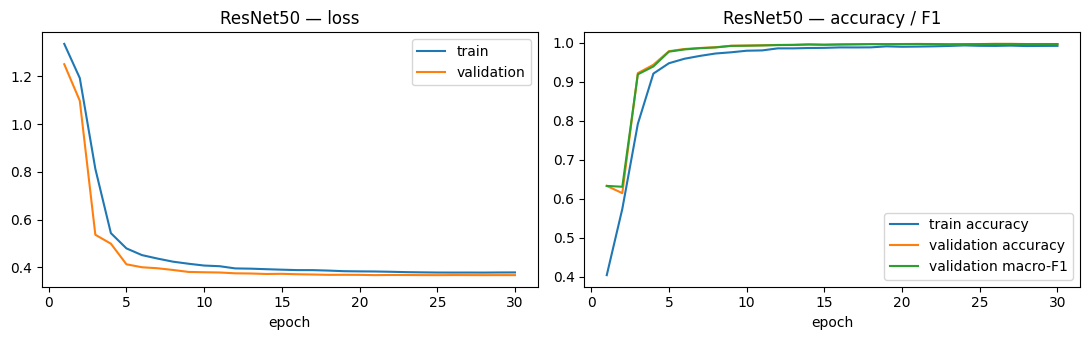

In [13]:
model, history = fit()
history.to_csv(OUT_DIR / "history.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history.epoch, history.train_loss, label="train"); ax[0].plot(history.epoch, history.val_loss, label="validation")
ax[0].set_title(f"{MODEL_KEY} — loss")
ax[1].plot(history.epoch, history.train_acc, label="train accuracy"); ax[1].plot(history.epoch, history.val_acc, label="validation accuracy")
ax[1].plot(history.epoch, history.val_f1, label="validation macro-F1"); ax[1].set_title(f"{MODEL_KEY} — accuracy / F1")
for a in ax: a.legend(); a.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(OUT_DIR / "figures/learning_curves.png", dpi=150); plt.show()

## 9. Evaluation Utilities

In [14]:
def compute_metrics(y, prob):
    pred = prob.argmax(1)
    P, R, F1, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    _, _, F1w, _ = precision_recall_fscore_support(y, pred, average="weighted", zero_division=0)
    try:
        auc = roc_auc_score(label_binarize(y, classes=range(NUM_CLASSES)), prob, average="macro")
    except ValueError:
        auc = np.nan
    return dict(accuracy=accuracy_score(y, pred), balanced_accuracy=balanced_accuracy_score(y, pred),
                precision_macro=P, recall_macro=R, f1_macro=F1, f1_weighted=F1w, roc_auc_macro=auc,
                cohen_kappa=cohen_kappa_score(y, pred), mcc=matthews_corrcoef(y, pred))

def bootstrap_ci(y, prob, n=N_BOOTSTRAP):
    rng = np.random.default_rng(SEED); pred = prob.argmax(1); acc, f1 = [], []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        acc.append(accuracy_score(y[i], pred[i])); f1.append(f1_score(y[i], pred[i], average="macro"))
    return np.percentile(acc, [2.5, 97.5]), np.percentile(f1, [2.5, 97.5])

def per_class_table(y, prob):
    rep = classification_report(y, prob.argmax(1), labels=range(NUM_CLASSES), target_names=NAMES,
                                output_dict=True, zero_division=0)
    t = pd.DataFrame(rep).T.loc[NAMES, ["precision", "recall", "f1-score", "support"]]
    yb = label_binarize(y, classes=range(NUM_CLASSES))
    t["roc_auc"] = [roc_auc_score(yb[:, k], prob[:, k]) if yb[:, k].any() else np.nan for k in range(NUM_CLASSES)]
    return t

def plot_confusion(y, prob, title, fname):
    cm = confusion_matrix(y, prob.argmax(1), labels=range(NUM_CLASSES))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, m, fmt, t in [(axes[0], cm, "d", "counts"), (axes[1], cmn, ".3f", "row-normalised")]:
        ax.imshow(m, cmap="Blues")
        for i in range(NUM_CLASSES):
            for j in range(NUM_CLASSES):
                ax.text(j, i, format(m[i, j], fmt), ha="center", va="center",
                        color="white" if m[i, j] > m.max() / 2 else "black")
        ax.set_xticks(range(NUM_CLASSES), NAMES, rotation=30); ax.set_yticks(range(NUM_CLASSES), NAMES)
        ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{title} ({t})")
    plt.tight_layout(); plt.savefig(fname, dpi=200); plt.show()

def plot_roc(y, prob, title, fname):
    yb = label_binarize(y, classes=range(NUM_CLASSES))
    plt.figure(figsize=(6, 5))
    for k in range(NUM_CLASSES):
        if yb[:, k].any():
            fpr, tpr, _ = roc_curve(yb[:, k], prob[:, k])
            plt.plot(fpr, tpr, label=f"{NAMES[k]} (AUC = {roc_auc_score(yb[:, k], prob[:, k]):.4f})")
    plt.plot([0, 1], [0, 1], "k--", lw=0.8); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
    plt.title(title); plt.legend(); plt.tight_layout(); plt.savefig(fname, dpi=200); plt.show()

## 10. Test-Set Results

### 10.1 Overall Performance

In [15]:
y_test = test_df.label.values
test_prob = predict(model, test_loader)
metrics = compute_metrics(y_test, test_prob)
(a_lo, a_hi), (f_lo, f_hi) = bootstrap_ci(y_test, test_prob)
results = pd.DataFrame([metrics], index=[MODEL_KEY]).round(4)
results["accuracy_95ci"] = f"[{a_lo:.4f}, {a_hi:.4f}]"
results["f1_macro_95ci"] = f"[{f_lo:.4f}, {f_hi:.4f}]"
results.to_csv(OUT_DIR / "test_results.csv")
np.savez(SHARED_DIR / "predictions" / f"{MODEL_KEY}.npz", prob=test_prob, y=y_test, path=test_df.path.values)
print(f"{MODEL_KEY} | protocol: {PROTOCOL} | test images: {len(y_test):,} | YOLO crops: {YOLO_DET_RAN}")
display(results)

ResNet50 | protocol: official_dedup | test images: 2,443 | YOLO crops: False


,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_macro,cohen_kappa,mcc,accuracy_95ci,f1_macro_95ci
ResNet50,0.9955,0.9957,0.9948,0.9957,0.9952,0.9955,1.0,0.9939,0.9939,"[0.9930, 0.9980]","[0.9925, 0.9979]"


### 10.2 Per-Class Performance

In [16]:
pc = per_class_table(y_test, test_prob)
pc.to_csv(OUT_DIR / "per_class.csv")
display(pc.round(4))

,precision,recall,f1-score,support,roc_auc
Difetto1,0.9974,0.9974,0.9974,765.0,1.0
Difetto2,0.9968,0.9921,0.9944,632.0,1.0
Difetto4,0.9867,1.0000,0.9933,446.0,1.0
No Defect,0.9983,0.9933,0.9958,600.0,1.0


### 10.3 Confusion Matrix and ROC Curves

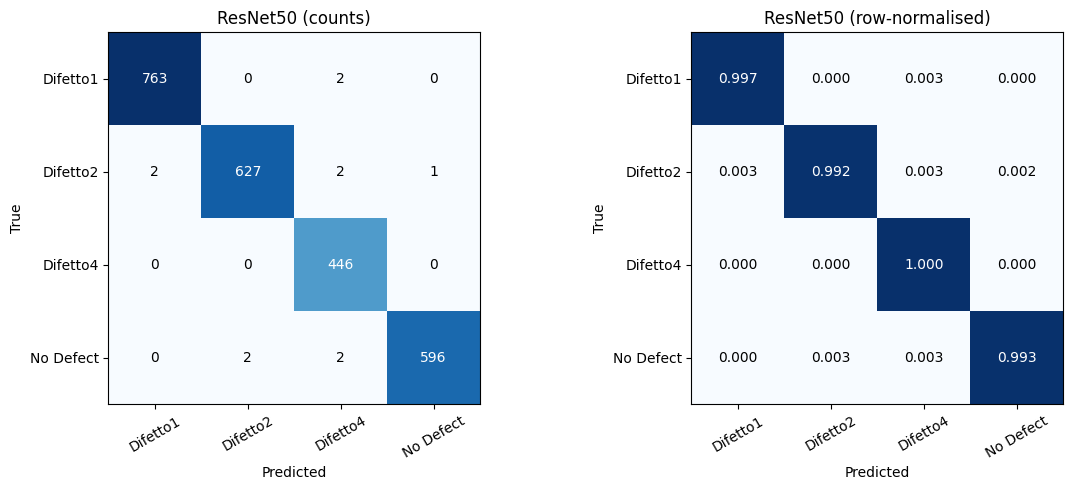

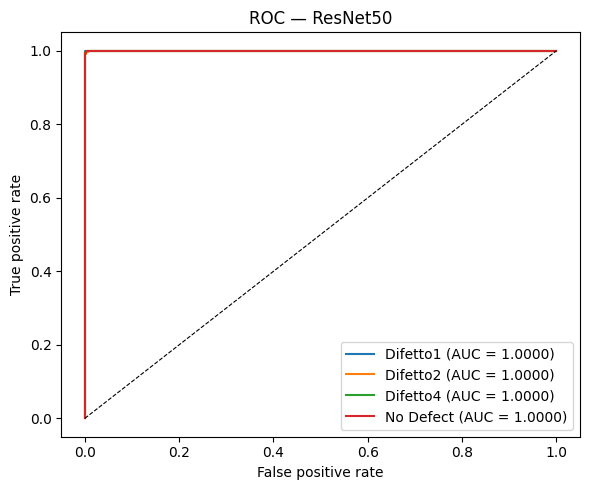

In [17]:
plot_confusion(y_test, test_prob, MODEL_KEY, OUT_DIR / "figures/confusion_matrix.png")
plot_roc(y_test, test_prob, f"ROC — {MODEL_KEY}", OUT_DIR / "figures/roc_curves.png")

### 10.4 Per-Weld Breakdown

In [18]:
t = test_df.assign(correct=test_prob.argmax(1) == y_test)
by_weld = (t.groupby(["weld", "cls"]).correct.agg(accuracy="mean", n="size").reset_index()
           .assign(errors=lambda d: ((1 - d.accuracy) * d.n).round().astype(int))
           .sort_values("errors", ascending=False))
by_weld.to_csv(OUT_DIR / "per_weld.csv", index=False)
display(by_weld.head(10).round(4))

,weld,cls,accuracy,n,errors
19,RRT-22R,Difetto1,0.9310,29,2
2,RRT-101R,NoDifetto,0.8750,8,1
50,RRT-88R,Difetto2,0.9524,21,1
51,RRT-88R,NoDifetto,0.9167,12,1
18,RRT-20R,NoDifetto,0.8333,6,1
4,RRT-102R,Difetto2,0.9231,13,1
31,RRT-28R,Difetto2,0.9730,37,1
25,RRT-26R,Difetto2,0.9828,58,1
54,RRT-90R,NoDifetto,0.8750,8,1
44,RRT-40R,Difetto2,0.9630,27,1


## 11. Explainability with Grad-CAM

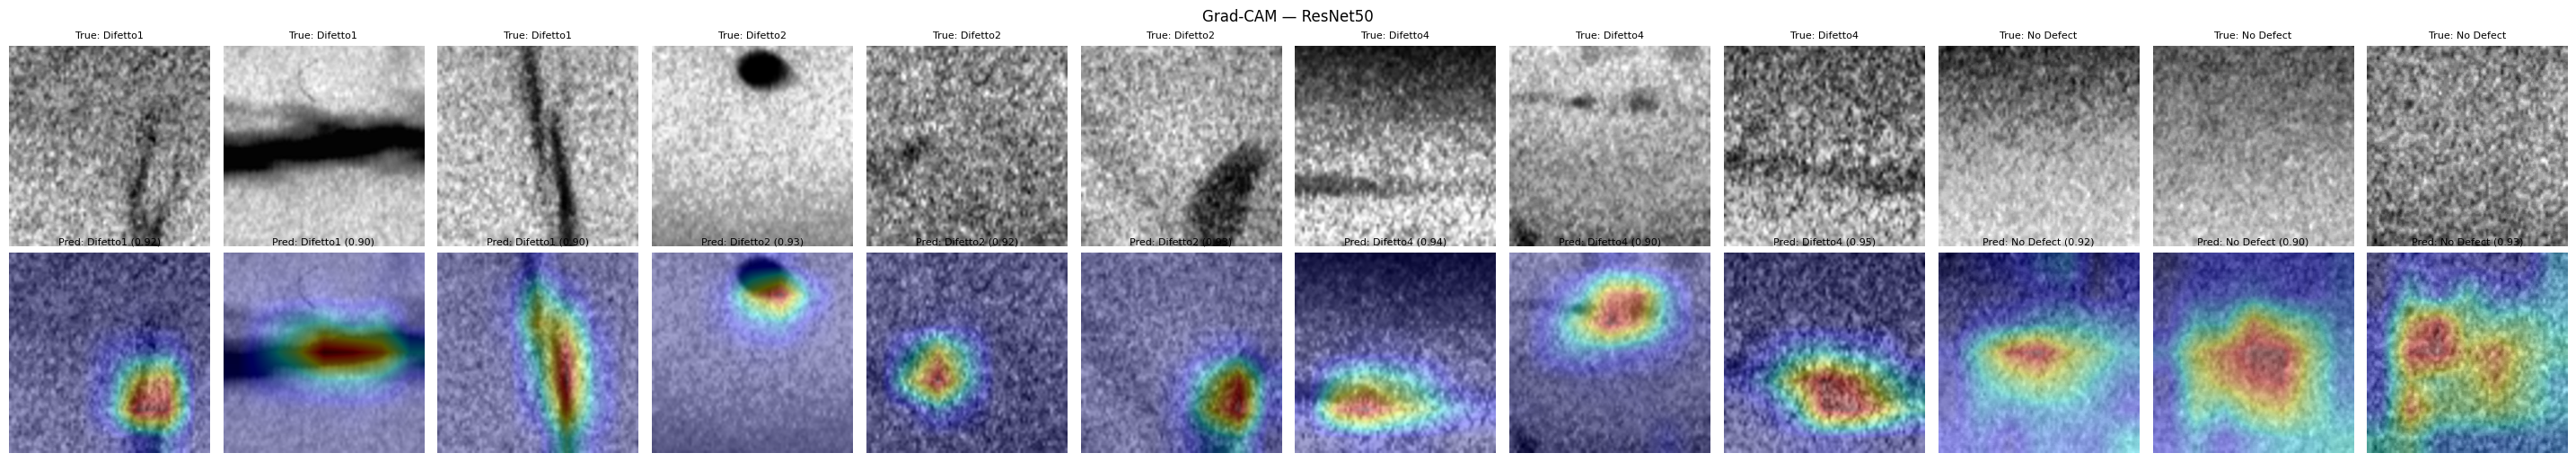

In [19]:
def gradcam(model, x):
    model.eval()
    with torch.enable_grad():
        feats = model.forward_features(x)
        feats.retain_grad()
        logits = model.forward_head(feats)
        model.zero_grad(set_to_none=True)
        logits.gather(1, logits.argmax(1).view(-1, 1)).sum().backward()
        cam = F.relu((feats.grad.mean((2, 3), keepdim=True) * feats).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        lo, hi = cam.amin((1, 2), keepdim=True), cam.amax((1, 2), keepdim=True)
        cam = (cam - lo) / (hi - lo + 1e-8)
    return cam.detach().cpu().numpy(), logits.softmax(1).detach().cpu().numpy()

n_show = 3
picks = pd.concat([test_df[test_df.label == k].sample(min(n_show, (test_df.label == k).sum()), random_state=SEED)
                   for k in range(NUM_CLASSES)])
xb = torch.stack([eval_tfm(Image.open(p).convert("L")) for p in picks.cls_path]).to(DEVICE)
cams, probs = gradcam(model, xb)
fig, axes = plt.subplots(2, len(picks), figsize=(2.4 * len(picks), 5.2), squeeze=False)
for c in range(len(picks)):
    raw = np.array(Image.open(picks.cls_path.iloc[c]).convert("L").resize((IMG_SIZE, IMG_SIZE)))
    axes[0, c].imshow(raw, cmap="gray")
    axes[0, c].set_title(f"True: {NAMES[picks.label.iloc[c]]}", fontsize=8)
    axes[1, c].imshow(raw, cmap="gray"); axes[1, c].imshow(cams[c], cmap="jet", alpha=0.35)
    axes[1, c].set_title(f"Pred: {NAMES[probs[c].argmax()]} ({probs[c].max():.2f})", fontsize=8)
    for a in axes[:, c]: a.axis("off")
plt.suptitle(f"Grad-CAM — {MODEL_KEY}"); plt.tight_layout()
plt.savefig(OUT_DIR / "figures/gradcam.png", dpi=200); plt.show()

## 12. Misclassification Analysis

Misclassified: 11 of 2,443


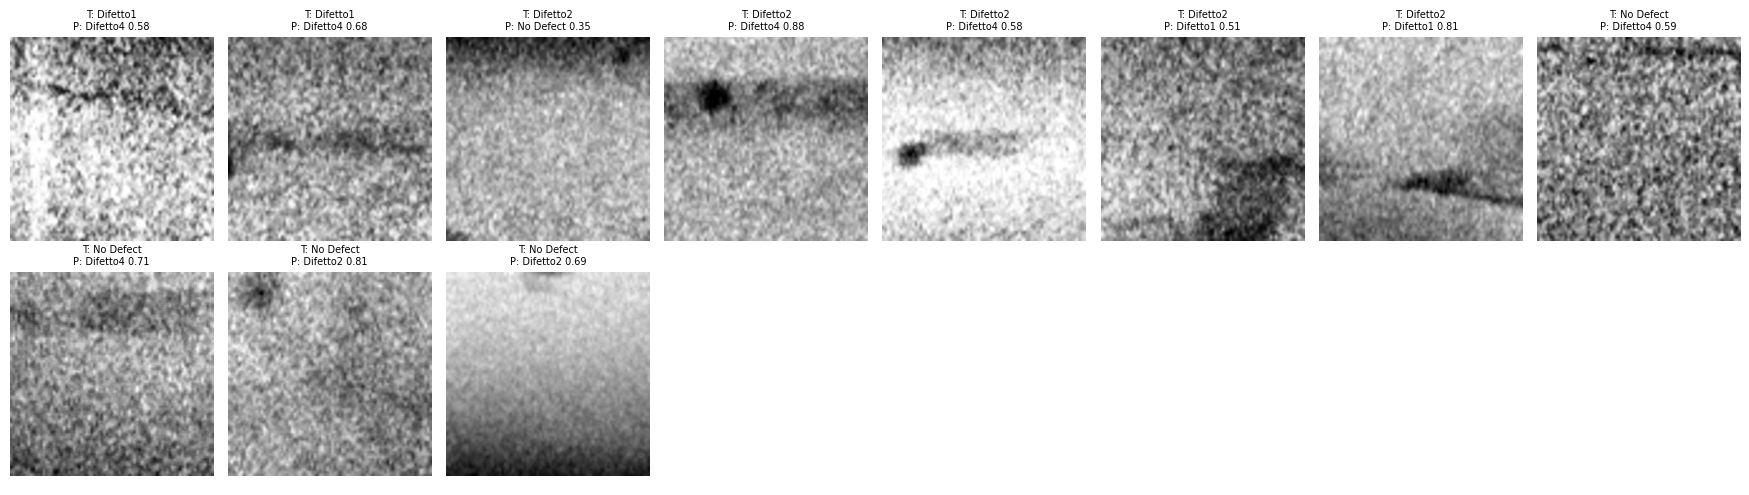

In [20]:
wrong = np.where(test_prob.argmax(1) != y_test)[0]
print(f"Misclassified: {len(wrong)} of {len(y_test):,}")
show = wrong[:24]
if len(show):
    cols = 8; rows = math.ceil(len(show) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(2.2 * cols, 2.5 * rows), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), show):
        ax.imshow(Image.open(test_df.cls_path.iloc[i]).convert("L"), cmap="gray")
        ax.set_title(f"T: {NAMES[y_test[i]]}\nP: {NAMES[test_prob[i].argmax()]} {test_prob[i].max():.2f}", fontsize=7)
    plt.tight_layout(); plt.savefig(OUT_DIR / "figures/misclassified.png", dpi=150); plt.show()

## 13. Experiment Summary Export

In [21]:
summary = dict(model=MODEL_KEY, timm_name=TIMM_NAME, protocol=PROTOCOL, yolo_detection_used=YOLO_DET_RAN,
               n_train=len(train_df), n_val=len(val_df), n_test=len(test_df),
               duplicates_removed=len(df_all) - len(df), img_size=IMG_SIZE, epochs_run=len(history),
               best_epoch=int(history.val_f1.idxmax() + 1), intensity_norm=INTENSITY_NORM, strong_aug=STRONG_AUG,
               tta=USE_TTA, test_metrics={k: round(float(v), 5) for k, v in metrics.items()})
(OUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
print("Saved to", OUT_DIR.resolve())

Saved to C:\Users\dipkh\Downloads\riawelc_outputs\official_dedup\ResNet50


## 14. Cross-Model Comparison and Soft-Voting Ensemble

In [22]:
pred_files = sorted((SHARED_DIR / "predictions").glob("*.npz"))
store = {f.stem: np.load(f, allow_pickle=True) for f in pred_files}
ref_paths = store[MODEL_KEY]["path"]
store = {k: v for k, v in store.items() if len(v["path"]) == len(ref_paths) and (v["path"] == ref_paths).all()}
rows = {k: compute_metrics(v["y"], v["prob"]) for k, v in store.items()}
if len(store) >= 2:
    ens = np.mean([v["prob"] for v in store.values()], 0)
    rows[f"Ensemble ({' + '.join(store)})"] = compute_metrics(y_test, ens)
    plot_confusion(y_test, ens, "Soft-voting ensemble", SHARED_DIR / "ensemble_confusion_matrix.png")
comparison = pd.DataFrame(rows).T.round(4)
comparison.to_csv(SHARED_DIR / "model_comparison.csv")
print(f"Models available: {list(store)}")
display(comparison)

Models available: ['ResNet50']


,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_macro,cohen_kappa,mcc
ResNet50,0.9955,0.9957,0.9948,0.9957,0.9952,0.9955,1.0,0.9939,0.9939
